# Sequential Data and Recurrent Neural Networks

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snss
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Example with toy sequences

In [3]:
x_seq = torch.FloatTensor([[1,], [2,], [3,]])
x_seq = x_seq.repeat(1, 2)
print(f"x_seq has shape {x_seq.shape} which means it is a sequence of {x_seq.shape[0]} {x_seq.shape[1]}-dimensional vectors")

x_seq has shape torch.Size([3, 2]) which means it is a sequence of 3 2-dimensional vectors


An RNN has a hidden state $h^{(t)}$ which receives two inputs: 

- the previous hidden state $h^{(t-1)}$
- the current input $x^{(t)}$

In [4]:
import torch.nn as nn
import torch.nn.functional as F

class RNN_Cell(nn.Module):
    def __init__(self, input_size=2, hidden_size=4):
        super().__init__()

        self.hidden_size = hidden_size

        # Weight and bias connecting previous hidden state
        self.w_hh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_hh = nn.Parameter(torch.zeros(hidden_size))
        
        # Weight and bias connecting inputs
        self.w_ih = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_ih = nn.Parameter(torch.zeros(hidden_size))

    def forward(self, x):
        """ x has size [B, t, c]
        """
        B, T, C = x.shape
        ht = torch.zeros([B, self.hidden_size], device=x.device, dtype=x.dtype)
        ot = torch.zeros([B, T, self.hidden_size], device=x.device, dtype=x.dtype)
        for t in range(T):
            xt = x[:, t, :]
            print(f'At t = {t}')
            print(f'\tInput = {xt.numpy()}')
            zt = xt @ self.w_ih.T + self.b_ih + \
                 ht @ self.w_hh.T + self.b_hh
            ht = F.tanh(zt)
            print(f'\tHidden = {ht.detach().numpy()}')
            ot[:, t, :] = ht

        return ot, ht
            
torch_RNN = nn.RNN(input_size=2, hidden_size=4, batch_first=True)
print("Ground truth")
print("------------")
output, hidden = torch_RNN(x_seq[None])
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)

print()
print("Our implementation")
print("------------------")
np.set_printoptions(precision=4)
cell = RNN_Cell()
with torch.no_grad():
    cell.w_hh[:] = torch_RNN.weight_hh_l0
    cell.b_hh[:] = torch_RNN.bias_hh_l0
    cell.w_ih[:] = torch_RNN.weight_ih_l0
    cell.b_ih[:] = torch_RNN.bias_ih_l0

output, hidden = cell(x_seq[None])

print()
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)       

Ground truth
------------
Output is of size torch.Size([1, 3, 4])
tensor([[[-0.2209, -0.5565, -0.5489,  0.4516],
         [ 0.4324, -0.7515, -0.8411,  0.7951],
         [ 0.8690, -0.8406, -0.9448,  0.8712]]], grad_fn=<TransposeBackward1>)

Last hidden is of size torch.Size([1, 1, 4])
tensor([[[ 0.8690, -0.8406, -0.9448,  0.8712]]], grad_fn=<StackBackward0>)

Our implementation
------------------
At t = 0
	Input = [[1. 1.]]
	Hidden = [[-0.2209 -0.5565 -0.5489  0.4516]]
At t = 1
	Input = [[2. 2.]]
	Hidden = [[ 0.4324 -0.7515 -0.8411  0.7951]]
At t = 2
	Input = [[3. 3.]]
	Hidden = [[ 0.869  -0.8406 -0.9448  0.8712]]

Output is of size torch.Size([1, 3, 4])
tensor([[[-0.2209, -0.5565, -0.5489,  0.4516],
         [ 0.4324, -0.7515, -0.8411,  0.7951],
         [ 0.8690, -0.8406, -0.9448,  0.8712]]], grad_fn=<CopySlices>)

Last hidden is of size torch.Size([1, 4])
tensor([[ 0.8690, -0.8406, -0.9448,  0.8712]], grad_fn=<TanhBackward0>)


## Classification example: IMDB sentiment database

In [5]:
!pip install pyarrow==15.0.2 datasets==4.0.0 transformers==5.0.0 numpy==1.26.4

  Using cached datasets-4.0.0-py3-none-any.whl.metadata (19 kB)
  Using cached transformers-5.0.0-py3-none-any.whl.metadata (37 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached multiprocess-0.70.16-py311-none-any.whl.metadata (7.2 kB)
  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
  Using cached regex-2026.9.29-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached tokenizers-0.22.2-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (7.3 kB)
  Using cached typer_slim-0.24.0-py3-none-any.whl.metadata (4.2 kB)
  Using cached safetensors-0.8.0-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.2 kB)
  Using cached aiohttp-3.14.5-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.

In [6]:
from datasets import load_dataset

imdb_dataset = load_dataset("stanfordnlp/imdb")

In [7]:
imdb_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [8]:
from torch.utils.data import Dataset, random_split, DataLoader

class IMDBDataset(Dataset):
    def __init__(self, hf_data):
        self.hf_data = hf_data

    def __len__(self):
        return len(self.hf_data)

    def __getitem__(self, idx):
        return {
            'text': self.hf_data[idx]['text'],
            'label': self.hf_data[idx]['label']
        }

train_val_dataset = IMDBDataset(imdb_dataset['train'])
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])

loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
batch = next(iter(loader))
print(batch['text'], batch['label'])

['Ying, a Chinese girl who speaks Czech, invited us to screening of a Czech movie (with English subtitles) in the Department of Visual and Environmental Studies (VES). It was the first time I saw Samotá&#345;i (Loners, 2000) and it was pretty good.<br /><br />Much like in many other Czech movies, the seven central characters seem to have a pretty difficult, dirty life; the web indicates that this theme was popular among the U.S. movies in the early 1990s. Their relationships are breaking up, combining, and recombining. Another typical feature of the Czech movies is that neither of the characters is designed to be a universally negative one and neither of them is a permanently positive character either. Also, you can see how the characters judge the features of others depending on the context; that\'s a very realistic feature of the movie\'s psychological analysis.<br /><br />Ond&#345;ej is a talented and married young surgeon who has two daughters. Nevertheless, you learn that he has o

In [9]:
train_val_dataset = imdb_dataset['train']
train_dataset, val_dataset = random_split(train_val_dataset, lengths=[0.8, 0.2])
test_dataset = imdb_dataset['test']

loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
batch = next(iter(loader))
print(batch['text'], batch['label'])

['I went into this film with expectations, from the hype, that it would be insightful and uplifting. Certainly something more than a cheap promotional for the band "Wilco."<br /><br />Instead we get a lot of moping and whining about "the process," a dishonorable and no doubt one-sided portrayal of one band members who was kicked out by the prima donna lead singer/songwriter, a gut-wrenching confession by the fallen member\'s friend -- for like 18 years -- saying the "friendship had run its course," and this whiny, uncompelling story about how one record label "hurt their feelings" by dumping them, only so that the band could immediately get 50 offers from other labels (oh, the tension...not!) They tried their best to make it look like it was a strain, but I suspect it was all smoke and mirrors to generate a tragedy that didn\'t exist. This doesn\'t even take into account the long stretches where we get many of their newest songs shoved at us in full without any storyline, insight or ev

### Preprocessing each sample

#### Tokenization

In [10]:
import re
def tokenize(sentence):
    # Remove HTML tags - anything that starts with <, ends with >, and doesn't contain a > inside
    sentence = re.sub('<[^>]*>', '', sentence)

    # Emoticon processing
    emoticons = re.findall('(?::|;|=)(?:-)?(?:\)|\(|D|P)', sentence.lower())

    # Standardize all whitespace and append emoticons to make sentiment processing easier
    sentence = re.sub('[\W]+', ' ', sentence.lower()) + ' '.join(emoticons).replace('-', '')

    return sentence.split()

text = '  your  :-) text   here <br/> :-)'
tokenize(text)

['your', 'text', 'here', ':)', ':)']

In [11]:
tokenize(batch['text'][0])

['i',
 'went',
 'into',
 'this',
 'film',
 'with',
 'expectations',
 'from',
 'the',
 'hype',
 'that',
 'it',
 'would',
 'be',
 'insightful',
 'and',
 'uplifting',
 'certainly',
 'something',
 'more',
 'than',
 'a',
 'cheap',
 'promotional',
 'for',
 'the',
 'band',
 'wilco',
 'instead',
 'we',
 'get',
 'a',
 'lot',
 'of',
 'moping',
 'and',
 'whining',
 'about',
 'the',
 'process',
 'a',
 'dishonorable',
 'and',
 'no',
 'doubt',
 'one',
 'sided',
 'portrayal',
 'of',
 'one',
 'band',
 'members',
 'who',
 'was',
 'kicked',
 'out',
 'by',
 'the',
 'prima',
 'donna',
 'lead',
 'singer',
 'songwriter',
 'a',
 'gut',
 'wrenching',
 'confession',
 'by',
 'the',
 'fallen',
 'member',
 's',
 'friend',
 'for',
 'like',
 '18',
 'years',
 'saying',
 'the',
 'friendship',
 'had',
 'run',
 'its',
 'course',
 'and',
 'this',
 'whiny',
 'uncompelling',
 'story',
 'about',
 'how',
 'one',
 'record',
 'label',
 'hurt',
 'their',
 'feelings',
 'by',
 'dumping',
 'them',
 'only',
 'so',
 'that',
 'the',

#### Vocabulary building

In [12]:
from collections import Counter
from tqdm import tqdm

def build_vocab_counts(dataset):
    vocab = Counter()
    for sample in tqdm(dataset):
        tokens = tokenize(sample['text'])
        vocab.update(tokens)
    return vocab

vocab_counts = build_vocab_counts(train_val_dataset)

100%|██████████| 25000/25000 [00:04<00:00, 5024.98it/s]


In [13]:
sorted(vocab_counts.items(), key = lambda x: x[1], reverse=True)[-20:]

[('pommies', 1),
 ('flamin', 1),
 ('abos', 1),
 ('yacca', 1),
 ('bonser', 1),
 ('donger', 1),
 ('sheilas', 1),
 ('everage', 1),
 ('poofters', 1),
 ('quantas', 1),
 ('gyppos', 1),
 ('earls', 1),
 ('rickmansworth', 1),
 ('chundering', 1),
 ('euphemisms', 1),
 ('covington', 1),
 ('snacka', 1),
 ('fitzgibbon', 1),
 ('dunny', 1),
 ('grossest', 1)]

In [14]:
vocab = {
    '<pad>': 0,
    '<unk>': 1, 
}
for idx, (token, count) in enumerate(sorted(vocab_counts.items(), key=lambda x : x[1], reverse=True)):
    vocab[token] = idx + 2

print(len(vocab))

75979


#### Sequence encoding

In [15]:
def encode_tokens(tokens):
    return [ vocab.get(token, vocab['<unk>']) for token in tokens]

encode_tokens(tokenize(batch['text'][0]))

[10,
 434,
 83,
 11,
 20,
 17,
 1385,
 38,
 2,
 3406,
 12,
 8,
 61,
 29,
 5898,
 3,
 5099,
 435,
 141,
 52,
 73,
 4,
 700,
 10637,
 16,
 2,
 1091,
 43172,
 306,
 69,
 75,
 4,
 175,
 5,
 43173,
 3,
 6642,
 44,
 2,
 1769,
 4,
 31808,
 3,
 58,
 815,
 30,
 7025,
 1136,
 5,
 30,
 1091,
 1050,
 36,
 14,
 4386,
 45,
 34,
 2,
 19117,
 3844,
 481,
 1911,
 13725,
 4,
 5599,
 6200,
 8496,
 34,
 2,
 2916,
 1648,
 13,
 444,
 16,
 39,
 3038,
 155,
 657,
 2,
 1861,
 68,
 515,
 92,
 261,
 3,
 11,
 6605,
 25674,
 63,
 44,
 87,
 30,
 1865,
 6127,
 1447,
 67,
 1412,
 34,
 16955,
 96,
 64,
 37,
 12,
 2,
 1091,
 97,
 1228,
 75,
 1191,
 1576,
 38,
 81,
 17218,
 440,
 2,
 1068,
 24,
 33,
 792,
 67,
 117,
 6,
 95,
 8,
 168,
 39,
 8,
 14,
 4,
 8615,
 19,
 10,
 1767,
 8,
 14,
 31,
 3765,
 3,
 5936,
 6,
 7205,
 4,
 1514,
 12,
 159,
 21,
 1772,
 11,
 151,
 21,
 59,
 192,
 83,
 2640,
 2,
 195,
 9128,
 118,
 69,
 75,
 109,
 5,
 67,
 12627,
 682,
 8565,
 32,
 179,
 9,
 366,
 206,
 100,
 762,
 2635,
 42,
 59,
 4,
 53

#### Putting it all together

In [16]:
def collate_fn(batch):
    """ This will be what DataLoader uses to process all of the samples together
    """
    texts, labels, lengths = [], [], []
    for sample in batch:
        tokens = tokenize(sample['text'])
        encoded = encode_tokens(tokens)
        texts.append(torch.tensor(encoded))
        labels.append(sample['label'])
        lengths.append(len(encoded))

    labels = torch.tensor(labels)
    lengths = torch.tensor(lengths)

    # Pad each sequence to have a common shape
    texts = nn.utils.rnn.pad_sequence(texts, batch_first=True)

    return texts, labels, lengths

loader = DataLoader(train_val_dataset, batch_size=2, shuffle=False, 
                    collate_fn=collate_fn)

batch = next(iter(loader))

print('Text batch:', batch[0].shape, batch[0].dtype)
print('Label batch:', batch[1].shape, batch[1].dtype)
print('Lengths batch:', batch[2])

Text batch: torch.Size([2, 291]) torch.int64
Label batch: torch.Size([2]) torch.int64
Lengths batch: tensor([291, 228])


In [17]:
# What does a padded sequence look like?
batch[0]

tensor([[   10,  1607,    10,   244,  1991,  4099,    38,    60,   370,  1109,
            86,     5,    31,     2,  7095,    12,  3397,     8,    54,     8,
            14,    84,   620,     9,  6811,    10,    82,   553,    12,    32,
            84,     8,    14, 19102,    34,  1190,    13,  9266,    46,     8,
           124,   792,     6,  2519,    11,   663,  1617,   111,     4,   334,
             5,   107,  1184,  3091,    10,    65,    68,     6,    66,    11,
            16,   541,     2,   112,     7,  3999,   187,     4,   185,  3924,
           452,  1425,   766,  4335,    36,   489,     6,   839,   286,    53,
            51,    44,   110,     9,   833,    53,   489,     6,  1134,    41,
         11898,     6,   229,    49,   432,     5,   650,    23,    48,     2,
           841, 26535,   196,    44,   802,   985,  1334,   140,    15,     2,
          2550,   324,     3,  1504,  1334,     9,     2,  2335,  1618,     9,
           199,  2246,  7277,     3,  1956, 19103,  

### Checking that it works

In [18]:
train_loader = DataLoader(train_dataset, batch_size=32, num_workers=2, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=32, num_workers=2, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=32, num_workers=2, shuffle=False, collate_fn=collate_fn)

In [19]:
from tqdm import tqdm
for batch in tqdm(train_loader):
    a = len(batch[0])
for batch in tqdm(val_loader):
    a = len(batch[0])
for batch in tqdm(test_loader):
    a = len(batch[1])

100%|██████████| 782/782 [00:05<00:00, 154.61it/s]


### The neural network part

In [20]:
# The embedding layer
# Role: convert the tokens (index of each word in the vocabulary) into a float-valued vector. 
# This is trainable. Ideally, similar words ("happy" "ecstatic" "joyful") get mapped to similar embeddings
#
# This is a lookup table. We don't apply activations. It just makes the network able to process the words easier

import torch.nn as nn

embedding = nn.Embedding(num_embeddings=len(vocab),
                         embedding_dim=5,
                         padding_idx=0)

embedding(batch[0])

tensor([[[ 0.2479,  1.2932, -0.6358,  0.4109, -1.1808],
         [ 1.1749,  1.3072,  0.1997, -0.7165,  0.1751],
         [-1.6811,  0.3445,  0.6239, -1.6965, -0.1272],
         ...,
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000]],

        [[-0.6953, -1.1784, -1.2069,  0.3019,  0.7441],
         [ 1.1450, -0.4860,  0.8701, -0.3199,  0.2850],
         [-0.6267,  0.3853,  2.8689,  0.9056,  0.1998],
         ...,
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000]],

        [[-0.7870, -1.4343, -0.6233, -0.3136,  0.1094],
         [ 1.3517, -0.2219,  0.4292, -1.5721, -0.9920],
         [ 0.0471, -0.7046, -0.2849,  0.5618,  1.4956],
         ...,
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
  

In [21]:
# Embedding turns this from a list of integers into a list of vectors
embedding(batch[0]).shape

torch.Size([8, 770, 5])

In [22]:
# Packing the sequence is useful for numerical efficiency. The elements from each batch element are interleaved
# to let them be processed without wasting computation on padding elements
nn.utils.rnn.pack_padded_sequence(embedding(batch[0]), batch[2], enforce_sorted=False, batch_first=True)

PackedSequence(data=tensor([[ 0.2139, -1.0111,  0.7977,  0.2365,  0.2288],
        [-0.7870, -1.4343, -0.6233, -0.3136,  0.1094],
        [-1.2845, -0.1079,  1.5384,  1.3041, -0.6044],
        ...,
        [ 0.7079, -1.8732, -0.2077,  0.0625, -0.9782],
        [ 2.2620,  0.6611, -0.3340,  1.2712, -1.3557],
        [ 1.4973, -0.2092, -0.9083, -0.6872, -0.5027]],
       grad_fn=<PackPaddedSequenceBackward0>), batch_sizes=tensor([8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
        8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 7, 7,
        6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 5,
        5, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
        4, 4, 4, 

In [23]:
import torch.nn.functional as F

class RNN_Model(nn.Module):
    def __init__(self, vocab_size, embedding_dim, rnn_size, fc_size):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings = vocab_size,
            embedding_dim = embedding_dim,
            padding_idx=0)

        self.rnn = nn.RNN(embedding_dim, rnn_size, batch_first=True)
        self.fc1 = nn.Linear(rnn_size, fc_size)
        self.fc2 = nn.Linear(fc_size, 2)

    def forward(self, text, lengths):
        x = self.embedding(text)
        x = nn.utils.rnn.pack_padded_sequence(
            x, lengths, enforce_sorted=False, batch_first=True)
        x, h = self.rnn(x)

        x = h[-1, :, :] # -1 to collect the last layer output

        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        return x

torch.manual_seed(42)
model = RNN_Model(
    vocab_size=len(vocab),
    embedding_dim=32,
    rnn_size=128,
    fc_size=128,
)
model

RNN_Model(
  (embedding): Embedding(75979, 32, padding_idx=0)
  (rnn): RNN(32, 128, batch_first=True)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

In [24]:
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split
from tqdm.notebook import tqdm, trange

def train(model, optimizer, loss_func, train_loader, val_loader, num_epochs=10):
    model = model.to(device)

    train_loss = []
    train_acc = []
    val_loss = []
    val_acc = []

    pbar_epoch = trange(num_epochs)
    for ii in pbar_epoch:
        model.train()
        train_loss_ = 0.
        train_correct_ = 0.
        for xb, yb, lengths in tqdm(train_loader, leave=False):
            # Send data to device
            xb = xb.to(device)
            yb = yb.to(device)

            # Make a prediction, compute the loss
            y_pred = model(xb, lengths.cpu().numpy())
            loss = loss_func(y_pred, yb)

            # Backpropagate, apply gradient updates, zero gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            train_loss_ += loss.item() * yb.shape[0]
            train_correct_ += (torch.argmax(y_pred, dim=1) == yb).float().sum().item()
            
        train_loss.append(train_loss_ / len(train_loader.dataset))
        train_acc.append(train_correct_ / len(train_loader.dataset))

        model.eval()
        with torch.no_grad():
            val_loss_ = 0.
            val_correct_ = 0.
            for xb, yb, lengths in tqdm(val_loader, leave=False):
                # Send data to device
                xb = xb.to(device)
                yb = yb.to(device)
                
                # Make a prediction, compute the loss
                y_pred = model(xb, lengths.cpu().numpy())
                loss = loss_func(y_pred, yb)

                # Logging
                val_loss_ += loss.item() * yb.shape[0]
                val_correct_ += (torch.argmax(y_pred, dim=1) == yb).float().sum().item()
            val_loss.append(val_loss_ / len(val_loader.dataset))
            val_acc.append(val_correct_ / len(val_loader.dataset))

        pbar_epoch.set_postfix(
            epoch=f"{ii+1:03d} / {num_epochs:03d}",
            train_loss=f"{train_loss[-1]:.3f}",
            train_acc=f"{train_acc[-1]:.3f}",
            val_loss=f"{val_loss[-1]:.3f}",
            val_acc=f"{val_acc[-1]:.3f}")

    return model, (train_loss, train_acc, val_loss, val_acc)

# Define a loss function and optimizer
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train(model, optimizer, loss, train_loader, val_loader, num_epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

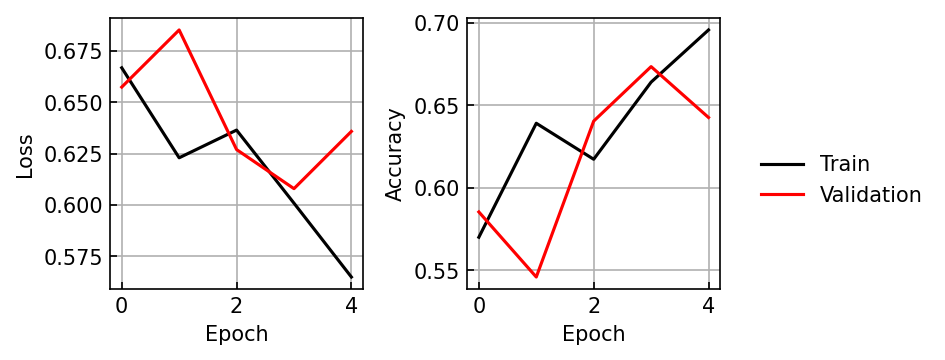

In [25]:
fig, ax = plt.subplots(1, 2, sharex=True, figsize=(5, 2.5))

ax[0].plot(model_stats[0], color='black', label='Train')
ax[0].plot(model_stats[2], color='red', label='Validation')
ax[0].set(xlabel='Epoch', ylabel='Loss')

ax[1].plot(model_stats[1], color='black', label='Train')
ax[1].plot(model_stats[3], color='red', label='Validation')
ax[1].set(xlabel='Epoch', ylabel='Accuracy')

fig.legend(*ax[1].get_legend_handles_labels(), 
           loc='center left', bbox_to_anchor=[1, 0.5], framealpha=0)

plt.tight_layout()

In [26]:
model.eval()
with torch.no_grad():
    test_correct_ = 0.
    for xb, yb, lengths in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        y_pred = model(xb, lengths.cpu().numpy())
        y_pred = torch.argmax(y_pred, dim=1)
        test_correct_ += (y_pred == yb).float().sum().item()
    test_acc = test_correct_ / len(test_loader.dataset)

print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/782 [00:00<?, ?it/s]

Test accuracy: 0.647


In [31]:
# Classify a single example
idx = np.random.choice(len(test_dataset))
sample = test_dataset[idx]
text = sample['text']
print('Comment:', text)
print()
print('True sentiment:', sample['label'])

# Convert comment with tokenizer, etc.
model.eval()
batch = collate_fn([sample,])
with torch.no_grad():
    y_pred = model(batch[0].to(device), batch[2])
    y_pred = F.softmax(y_pred, dim=1)

print('Predicted probability:', y_pred[0].cpu().numpy())

Comment: A young theater actress reluctantly accepts her first major part in a staged play as Lady Macbeth thanks to the mishap of the production's diva falling in front of a moving car. A success winning her accolades, Betty(Christina Marsillach)finds instead horror as the one responsible for getting her to this point terrorizes her in cruel ways.<br /><br />First her stage manager boyfriend, Stefano(William McNamara)is viciously stabbed with a knife while she has to watch, rope-tied to a pillar in his uncle's vast mansion, keeping her eyes from closing thanks to needles scotch-taped under her eyes, with pricking a result if she blinks. Allowing her to escape, Betty again finds herself in this unfortunate position, when a specific gold chain is found on her Lady Macbeth wardrobe that had been torn to shreds by the madman after killing a series of crows which escaped from their cage in the equipment room, by the clothing designer who is first knocked to the floor by an iron and subsequ

## Implementing an LSTM cell

In [32]:
x_seq = torch.FloatTensor([[1,], [2,], [3,]])
x_seq = x_seq.repeat(1, 2)
print(f"x_seq has shape {x_seq.shape} which means it is a sequence of {x_seq.shape[0]} {x_seq.shape[1]}-dimensional vectors")

x_seq has shape torch.Size([3, 2]) which means it is a sequence of 3 2-dimensional vectors


An LSTM has a hidden state $h^{(t)}$ and a cell state $c^{(t)}$.
It contains a set of **gating functions** that allow the model to input/update ($i^{(t)}$), forget ($f^{(t)}$), and output ($o^{(t)}$)

Each gate ($i^{(t)},f^{(t)},o^{(t)}$ each receive inputs from the previous hidden state $h^{(t-1)}$ and the current input $x^{(t)}$

The gating functions are given by
\begin{align}
    i^{(t)} &= \sigma\left( W_{ii} x^{(t)} + b_{ii} + W_{hi} h^{(t-1)} + b_{hi} \right) \\
    f^{(t)} &= \sigma\left( W_{if} x^{(t)} + b_{if} + W_{hf} h^{(t-1)} + b_{hf} \right) \\
    o^{(t)} &= \sigma\left( W_{io} x^{(t)} + b_{io} + W_{ho} h^{(t-1)} + b_{ho} \right) \\
\end{align}

There is also a cell input $g^{(t)}$
\begin{align}
    g^{(t)} &= \tanh \left( W_{ig} x^{(t)} + b_{ig} + W_{hg} h^{(t-1)} + b_{hg} \right) \\
\end{align}

The **cell state** $c^{(t)}$ uses the **forget gate** to determine whether to discard the previous cell state $c^{(t-1)}$ and the **input gate** to determine whether to accept the new input $g^{(t)}$

\begin{align}
    c^{(t)} &= f^{(t)} c^{(t-1)} + i^{(t)} g^{(t)}
\end{align}

The **hidden** state of the LSTM is then the product of the activated cell state and the output gate.
\begin{align}
    h^{(t)} &= o^{(t)} \tanh c^{(t)}
\end{align}

In [33]:
import torch.nn as nn
import torch.nn.functional as F

class LSTM_Cell(nn.Module):
    def __init__(self, input_size=2, hidden_size=4):
        super().__init__()

        self.hidden_size = hidden_size

        # Input gate weight and biases
        self.w_ii = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_ii = nn.Parameter(torch.zeros(hidden_size))

        self.w_ih = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_ih = nn.Parameter(torch.zeros(hidden_size))

        # Forget gate weight and biases
        self.w_fi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_fi = nn.Parameter(torch.zeros(hidden_size))

        self.w_fh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_fh = nn.Parameter(torch.zeros(hidden_size))

        # Cell input weight and biases
        self.w_gi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_gi = nn.Parameter(torch.zeros(hidden_size))

        self.w_gh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_gh = nn.Parameter(torch.zeros(hidden_size))
        
        # Output gate weight and biases
        self.w_oi = nn.Parameter(torch.randn(size=(hidden_size, input_size)))
        self.b_oi = nn.Parameter(torch.zeros(hidden_size))

        self.w_oh = nn.Parameter(torch.randn(size=(hidden_size, hidden_size)))
        self.b_oh = nn.Parameter(torch.zeros(hidden_size))
        
    def forward(self, x):
        """ x has size [B, t, c]
        """
        B, T, C = x.shape
        ht = torch.zeros([B, self.hidden_size], dtype=x.dtype, device=x.device)
        ct = torch.zeros([B, self.hidden_size], dtype=x.dtype, device=x.device)

        outputs = torch.zeros([B, T, self.hidden_size], dtype=x.dtype, device=x.device)
        for t in range(T):
            xt = x[:, t, :]
            print(f'At t = {t}')
            print(f'\tInput = {xt.numpy()}')

            # Compute the input and forget gates so I can do the cell update
            it = F.sigmoid(
                xt @ self.w_ii.T + self.b_ii +
                ht @ self.w_ih.T + self.b_ih
            )
            ft = F.sigmoid(
                xt @ self.w_fi.T + self.b_fi +
                ht @ self.w_fh.T + self.b_fh
            )

            # Compute my cell update information
            gt = F.tanh(
                xt @ self.w_gi.T + self.b_gi +
                ht @ self.w_gh.T + self.b_gh
            )

            ct = ft * ct + it * gt
            print(f'\tCell = {ct.detach().cpu().numpy()}')

            # How much of the memory cell do I output?
            ot = F.sigmoid(
                xt @ self.w_oi.T + self.b_oi +
                ht @ self.w_oh.T + self.b_oh
            )
            ht = ot * F.tanh(ct)
            print(f'\tHidden = {ht.detach().cpu().numpy()}')
            outputs[:, t, :] = ht

        return output, (ht, ct)


torch_LSTM = nn.LSTM(input_size=2, hidden_size=4, batch_first=True)
print("Ground truth")
print("------------")
output, (hidden, cell) = torch_LSTM(x_seq[None])
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)
print()
print(f"Last cell is of size {cell.shape}")
print(cell)

print()
print("Our implementation")
print("------------------")
np.set_printoptions(precision=4)
lstm = LSTM_Cell()
with torch.no_grad():
    lstm.w_ii[:] = torch_LSTM.weight_ih_l0[0:4]
    lstm.b_ii[:] = torch_LSTM.bias_ih_l0[0:4]
    lstm.w_ih[:] = torch_LSTM.weight_hh_l0[0:4]
    lstm.b_ih[:] = torch_LSTM.bias_hh_l0[0:4]

    lstm.w_fi[:] = torch_LSTM.weight_ih_l0[4:8]
    lstm.b_fi[:] = torch_LSTM.bias_ih_l0[4:8]
    lstm.w_fh[:] = torch_LSTM.weight_hh_l0[4:8]
    lstm.b_fh[:] = torch_LSTM.bias_hh_l0[4:8]

    lstm.w_gi[:] = torch_LSTM.weight_ih_l0[8:12]
    lstm.b_gi[:] = torch_LSTM.bias_ih_l0[8:12]
    lstm.w_gh[:] = torch_LSTM.weight_hh_l0[8:12]
    lstm.b_gh[:] = torch_LSTM.bias_hh_l0[8:12]

    lstm.w_oi[:] = torch_LSTM.weight_ih_l0[12:16]
    lstm.b_oi[:] = torch_LSTM.bias_ih_l0[12:16]
    lstm.w_oh[:] = torch_LSTM.weight_hh_l0[12:16]
    lstm.b_oh[:] = torch_LSTM.bias_hh_l0[12:16]

output, (hidden, cell) = lstm(x_seq[None])

print()
print(f"Output is of size {output.shape}")
print(output)
print()
print(f"Last hidden is of size {hidden.shape}")
print(hidden)
print()
print(f"Last cell is of size {cell.shape}")
print(cell)

Ground truth
------------
Output is of size torch.Size([1, 3, 4])
tensor([[[-0.0251, -0.0371, -0.1357,  0.0286],
         [-0.1091, -0.0206, -0.2578, -0.0543],
         [-0.1423, -0.0065, -0.3741, -0.0532]]], grad_fn=<TransposeBackward0>)

Last hidden is of size torch.Size([1, 1, 4])
tensor([[[-0.1423, -0.0065, -0.3741, -0.0532]]], grad_fn=<StackBackward0>)

Last cell is of size torch.Size([1, 1, 4])
tensor([[[-0.7170, -0.0729, -0.7173, -0.1713]]], grad_fn=<StackBackward0>)

Our implementation
------------------
At t = 0
	Input = [[1. 1.]]
	Cell = [[-0.086  -0.1008 -0.2536  0.061 ]]
	Hidden = [[-0.0251 -0.0371 -0.1357  0.0286]]
At t = 1
	Input = [[2. 2.]]
	Cell = [[-0.4374 -0.105  -0.4843 -0.138 ]]
	Hidden = [[-0.1091 -0.0206 -0.2578 -0.0543]]
At t = 2
	Input = [[3. 3.]]
	Cell = [[-0.717  -0.0729 -0.7173 -0.1713]]
	Hidden = [[-0.1423 -0.0065 -0.3741 -0.0532]]

Output is of size torch.Size([1, 3, 4])
tensor([[[-0.0251, -0.0371, -0.1357,  0.0286],
         [-0.1091, -0.0206, -0.2578, -0.

In [36]:
import torch.nn.functional as F

class LSTM_Model(nn.Module):
    def __init__(self, vocab_size, embedding_dim, rnn_size, fc_size):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_size,
                                      embedding_dim=embedding_dim,
                                      padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, rnn_size, batch_first=True)
        self.fc1 = nn.Linear(rnn_size, fc_size)
        self.fc2 = nn.Linear(fc_size, 2) 

    def forward(self, text, lengths):
        x = self.embedding(text)
        x = nn.utils.rnn.pack_padded_sequence(x, lengths, enforce_sorted=False, batch_first=True)
        x, (h, c) = self.lstm(x)

        x = h[-1, :, :]
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        return x


torch.manual_seed(42)
model = LSTM_Model(
    vocab_size=len(vocab),# tokenizer.vocab_size,
    embedding_dim=32,
    rnn_size=128,
    fc_size=128
)
model

LSTM_Model(
  (embedding): Embedding(75979, 32, padding_idx=0)
  (lstm): LSTM(32, 128, batch_first=True)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

In [37]:
# Define a loss function and optimizer
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, model_stats = train(model, optimizer, loss, train_loader, val_loader, num_epochs=5)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

In [38]:
model.eval()
with torch.no_grad():
    test_correct_ = 0.
    for xb, yb, lengths in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        yb = yb.to(device)
        y_pred = model(xb, lengths.cpu().numpy())
        y_pred = torch.argmax(y_pred, dim=1)
        test_correct_ += (y_pred == yb).float().sum().item()
    test_acc = test_correct_ / len(test_loader.dataset)

print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/782 [00:00<?, ?it/s]

Test accuracy: 0.815


In [40]:
# Classify a single example
idx = np.random.choice(len(test_dataset))
sample = test_dataset[idx]
text = sample['text']
print('Comment:', text)
print()
print('True sentiment:', sample['label'])

# Convert comment with tokenizer, etc.
model.eval()
batch = collate_fn([sample,])
with torch.no_grad():
    y_pred = model(batch[0].to(device), batch[2])
    y_pred = F.softmax(y_pred, dim=1)

print('Predicted probability:', y_pred[0].cpu().numpy())

Comment: I have just finished watching this film for the first time, and I must say that I am very impressed.<br /><br />How bleak. How full of despair. How nightmarish. Incredible.<br /><br />Visually stunning, several scenes are embedded in my mind...the first appearance of the phantom carriage...the soul of David Holm as it rises from his corpse...his spirit on his knees, pleading.<br /><br />This film takes a simple story-that of the ghostly driver of the phantom carriage, doomed to collect the souls of the dead for a year-brings it into the present setting of the film and then uses flashbacks as a means to explain how David Holm ends up in his predicament.<br /><br />I would love to see this released on DVD so that more might see it. Everyone should.

True sentiment: 1
Predicted probability: [0.01 0.99]
